# 💬 Análise de Sentimento de Reviews de Produtos

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** classificação binária de textos (NLP)

> **Resumo:** construímos um modelo que lê reviews de clientes da Amazon Alexa e identifica automaticamente os **negativos**, para que o time de atendimento consiga agir rápido com os clientes insatisfeitos.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados
- **FASE 03:** Modelagem dos Dados
- **FASE 04:** Avaliação
- **FASE 05:** Implantação
- **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** estrutura CRISP-DM e correções de metodologia em relação à versão original (que foi mantida no repositório para mostrar a evolução): remoção de duplicadas antes da divisão treino/teste, pipeline sem vazamento, negações mantidas no texto, métricas focadas na classe negativa e limiar escolhido sem usar o teste. Executado com Python 3.13, pandas 3.0 e scikit-learn 1.9.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Empresas recebem diariamente centenas de avaliações de clientes em sites e redes sociais. Ler tudo manualmente é inviável, e um cliente insatisfeito sem resposta pode virar uma reclamação pública, uma devolução ou um cliente perdido.

Nesta base, temos **reviews reais de clientes dos produtos Amazon Alexa** (Echo, Echo Dot, Fire TV Stick etc.), com o texto escrito pelo cliente, a nota de 1 a 5 e a variação do produto.

**Fonte dos dados:** [Amazon Alexa Reviews – Kaggle](https://www.kaggle.com/sid321axn/amazon-alexa-reviews)

## 🎯 Objetivo

Construir um classificador que receba o **texto de um review** e indique se ele é **positivo ou negativo**, priorizando **encontrar os reviews negativos**.

> **Pergunta de negócio:** *É possível identificar automaticamente os clientes insatisfeitos a partir do que eles escrevem, para que o time de atendimento aja antes que o problema cresça?*

**Stakeholder:** time de Relacionamento com o Cliente / Relações Públicas.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | Review (uma linha = uma avaliação de um cliente) |
| **Tipo de problema** | Classificação binária supervisionada: **1 = review negativo**, 0 = review positivo |
| **Desafio principal** | Base **desbalanceada**: apenas ~8% dos reviews são negativos |
| **Métrica principal** | **Recall e F1 da classe negativa**: o importante é encontrar os clientes insatisfeitos, sem gerar alertas falsos demais |
| **Entrega** | Modelo salvo + app Streamlit que classifica um review e mostra as palavras que pesaram na decisão |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir o problema, a métrica e o formato da entrega |
| **02. Preparação dos dados** | Limpar (nulos, vazios e duplicados), explorar os textos (EDA) e criar variáveis |
| **03. Modelagem** | Transformar texto em números (TF-IDF), comparar modelos, ajustar hiperparâmetros, escolher o limiar e testar calibração |
| **04. Avaliação** | Medir o modelo no teste, ler os acertos e erros e descobrir as palavras mais importantes |
| **05. Implantação** | Salvar o modelo e simular reviews novos |

# FASE 02: PREPARAÇÃO DOS DADOS

Nesta fase vamos **conhecer e preparar a base**: carregar os dados, conferir a qualidade (nulos, textos vazios e duplicados), explorar os textos e criar as variáveis usadas no modelo.

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys
import pickle

import numpy             as np
import pandas            as pd
import seaborn           as sns
import matplotlib.pyplot as plt

from scipy.stats                     import loguniform
from sklearn.model_selection         import (train_test_split, StratifiedKFold, cross_validate,
                                             cross_val_predict, RandomizedSearchCV)
from sklearn.compose                 import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing           import OneHotEncoder
from sklearn.linear_model            import LogisticRegression
from sklearn.naive_bayes             import MultinomialNB
from sklearn.svm                     import LinearSVC
from sklearn.calibration             import CalibratedClassifierCV, calibration_curve
from sklearn.metrics                 import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                                             precision_recall_curve, precision_score, recall_score, f1_score,
                                             average_precision_score, brier_score_loss)
from imblearn.pipeline               import Pipeline
from imblearn.over_sampling          import SMOTE

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 150)

#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** do projeto:

| Arquivo | Função | Para que serve |
|---|---|---|
| `src/texto.py` | `limpar_texto` | Minúsculas, "n't" → "not", remove pontuação e stopwords (**mantendo as negações**) |
| `src/texto.py` | `contribuicao_palavras` | Mostra as palavras que mais pesaram na previsão de um review (usado no app) |
| `src/selecao.py` | `importancia_random_forest`, `selecao_features` | Seleção de variáveis por Random Forest e por Informação Mútua (`SelectKBest`) |
| `src/graficos.py` | `plot_distribuicao_alvo`, `plot_barras`, `plot_nuvem`, `plot_top_palavras` | Gráficos padronizados, salvos em `Imagens/` |

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.texto    import limpar_texto, contribuicao_palavras, STOPWORDS, NEGACOES
from src.graficos import plot_distribuicao_alvo, plot_barras, plot_nuvem, plot_top_palavras, salvar
from src.selecao  import importancia_random_forest, selecao_features

### 1.2. Salvar a base em CSV

A base vem do Kaggle no formato **TSV** (separado por tabulação) e já está no repositório em `Datasets/amazon_alexa.tsv`. Aqui fazemos a leitura; depois da limpeza (item 2.4), salvamos uma **base limpa em CSV** (`Datasets/amazon_alexa_limpo.csv`).

In [3]:
df = pd.read_csv('../Datasets/amazon_alexa.tsv', sep='\t')

## 2 - LIMPEZA DOS DADOS

Antes de modelar, precisamos garantir que os dados são **confiáveis**. Em textos, além de nulos, é importante procurar **textos vazios** e **reviews duplicados**.

### 2.1. Leitura dos dados

In [4]:
df.head()

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer a question correctly but Alexa says you got it wrong and answers the same as you. I like being abl...",1
3,5,31-Jul-18,Charcoal Fabric,"I have had a lot of fun with this thing. My 4 yr old learns about dinosaurs, i control the lights and play games like categories. Has nice sound w...",1
4,5,31-Jul-18,Charcoal Fabric,Music,1


#### 📖 Dicionário de dados

| Variável | Descrição |
|---|---|
| `rating` | Nota que o cliente deu ao produto (1 a 5) |
| `date` | Data em que o review foi publicado |
| `variation` | Variação do produto (modelo e cor, ex.: *Black Dot*, *Charcoal Fabric*) |
| `verified_reviews` | **Texto** escrito pelo cliente |
| `feedback` | **Variável alvo original**: 1 = positivo · 0 = negativo (criada a partir da nota) |

### 2.2. Colunas

In [5]:
print(df.columns.tolist())

['rating', 'date', 'variation', 'verified_reviews', 'feedback']


### 2.3. Dimensões de dados

In [6]:
print(f'Linhas: {df.shape[0]} | Colunas: {df.shape[1]}')
df.nunique()

Linhas: 3150 | Colunas: 5


rating                 5
date                  77
variation             16
verified_reviews    2300
feedback               2
dtype: int64

📌 **Nota**
- 🔎 A base tem **3.150 reviews**, mas apenas **2.300 textos diferentes**: há muitos textos repetidos, investigados no próximo item.
- 🔎 `variation` tem **16 variações** de produto, e `date` cobre apenas **77 dias** (16/05/2018 a 31/07/2018).

### 2.4. Check dados nulos

In [7]:
textos = df['verified_reviews'].fillna('').str.strip()

print(f'Valores nulos por coluna:\n{df.isnull().sum()}\n')
print(f'Textos vazios (só espaços): {(textos == "").sum()}')
print(f'Linhas duplicadas (todas as colunas iguais): {df.duplicated().sum()}')

Valores nulos por coluna:
rating              0
date                0
variation           0
verified_reviews    1
feedback            0
dtype: int64

Textos vazios (só espaços): 80
Linhas duplicadas (todas as colunas iguais): 715


In [8]:
# Exemplos de reviews duplicados
df[df.duplicated(keep=False)].sort_values('verified_reviews').head(6)

,rating,date,variation,verified_reviews,feedback
85,5,30-Jul-18,Heather Gray Fabric,,1
183,3,29-Jul-18,Heather Gray Fabric,,1
219,5,29-Jul-18,Sandstone Fabric,,1
780,5,30-Jul-18,Heather Gray Fabric,,1
878,3,29-Jul-18,Heather Gray Fabric,,1
914,5,29-Jul-18,Sandstone Fabric,,1


📌 **Nota**
- 🔎 Há **80 textos vazios** e **1 nulo**: sem texto não há o que classificar.
- 🔎 Há **715 linhas duplicadas (22,7% da base)**: mesmo texto, nota, data e variação. Provavelmente o mesmo review foi coletado mais de uma vez.
- ⚠️ **Por que isso importa?** Se um review duplicado cair no treino e sua cópia no teste, o modelo é avaliado em um texto que ele **já viu**, e as métricas ficam **otimistas demais**. A versão original não tratava isso.
- ✅ **Decisão:** remover textos vazios e linhas duplicadas **antes** de dividir treino e teste.

In [9]:
df['verified_reviews'] = df['verified_reviews'].fillna('').str.strip()
df_limpo = df[df['verified_reviews'] != ''].drop_duplicates().reset_index(drop=True)

print(f'{len(df)} → {len(df_limpo)} reviews ({len(df) - len(df_limpo)} removidos)')

df_limpo.to_csv('../Datasets/amazon_alexa_limpo.csv', index=False)

3150 → 2384 reviews (766 removidos)


### 2.5. Estatística descritiva

#### 2.5.1. Separando os tipos de variáveis

In [10]:
num_cols = df_limpo.select_dtypes(include='number').columns.tolist()
cat_cols = df_limpo.select_dtypes(exclude='number').columns.tolist()

print(f'Numéricas: {num_cols}')
print(f'Categóricas/texto: {cat_cols}')

Numéricas: ['rating', 'feedback']
Categóricas/texto: ['date', 'variation', 'verified_reviews']


#### 2.5.2. Colunas numéricas

In [11]:
df_limpo[num_cols].describe().round(2)

,rating,feedback
count,2384.00,2384.00
mean,4.46,0.91
std,1.09,0.28
min,1.00,0.00
25%,4.00,1.00
50%,5.00,1.00
75%,5.00,1.00
max,5.00,1.00


In [12]:
# Como o feedback foi criado a partir da nota?
pd.crosstab(df_limpo['rating'], df_limpo['feedback'], margins=True)

feedback,0,1,All
rating,,,
1,129,0,129
2,76,0,76
3,0,106,106
4,0,340,340
5,0,1733,1733
All,205,2179,2384


📌 **Nota**
- 🔎 A nota média é **4,46**, e metade dos clientes dá nota 5: a maioria está satisfeita.
- 🔎 Pela tabela cruzada, a regra do rótulo é: **notas 1 e 2 → negativo** e **notas 3, 4 e 5 → positivo**.
- ⚠️ A versão original dizia que a nota 3 era negativa, mas os dados mostram que **reviews nota 3 são rotulados como positivos** (106 reviews). Isso é uma **limitação do rótulo**: parte deles pode conter críticas.
- ✅ A coluna `rating` **não pode** ser usada como variável do modelo: ela é a própria origem do rótulo (seria "colar a resposta").

#### 2.5.3. Colunas Categóricas

In [13]:
print(df_limpo['variation'].value_counts(), '\n')

datas = pd.to_datetime(df_limpo['date'], format='%d-%b-%y')
print(f'Período: {datas.min():%d/%m/%Y} a {datas.max():%d/%m/%Y}')

variation
Configuration: Fire TV Stick    336
Black  Plus                     261
Black                           258
Black  Show                     256
Black  Dot                      247
Black  Spot                     235
Charcoal Fabric                 219
White  Spot                     104
White  Dot                       90
White                            87
White  Show                      82
Heather Gray Fabric              77
White  Plus                      76
Sandstone Fabric                 44
Oak Finish                        7
Walnut Finish                     5
Name: count, dtype: int64 

Período: 16/05/2018 a 31/07/2018


📌 **Nota**
- 🔎 As variações mais avaliadas são **Fire TV Stick (336), Black Plus (261) e Black (258)**.
- 🔎 Os reviews cobrem um período curto (16/05/2018 a 31/07/2018), então não há como analisar tendência ao longo do tempo. A coluna `date` não será usada no modelo.

### 2.6. Verificando outliers

Em textos, o "outlier" mais comum é o **tamanho**: reviews muito curtos (ex.: um emoji) ou muito longos. Criamos duas variáveis de apoio: `length` (nº de caracteres) e `n_palavras`.

In [14]:
df_limpo['length'] = df_limpo['verified_reviews'].str.len()
df_limpo['n_palavras'] = df_limpo['verified_reviews'].str.split().str.len()

df_limpo[['length', 'n_palavras']].describe().round(1)

,length,n_palavras
count,2384.0,2384.0
mean,140.8,26.9
std,193.4,36.6
min,1.0,1.0
25%,33.0,6.0
50%,79.0,15.0
75%,174.0,34.0
max,2851.0,526.0


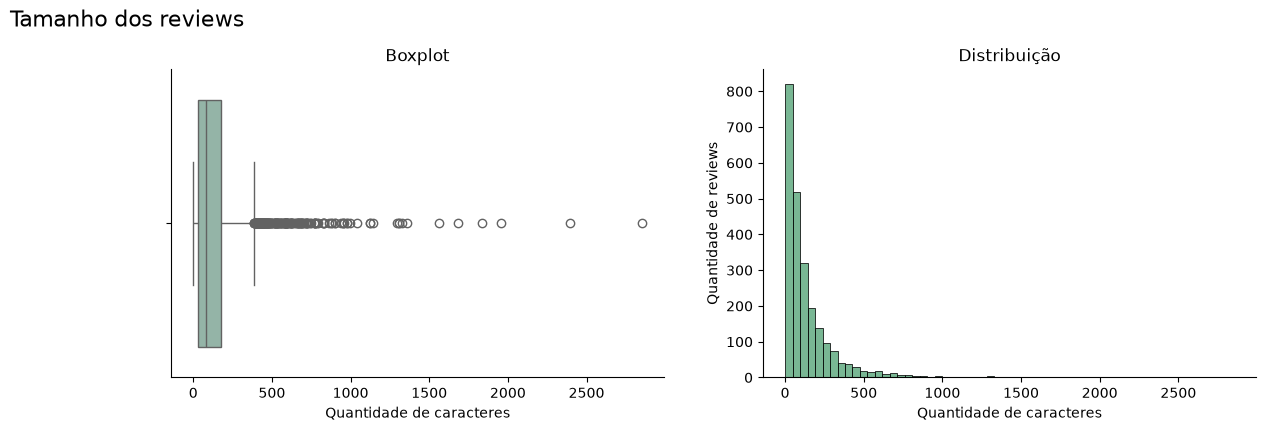

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df_limpo['length'], ax=ax[0], color='#8FB9A8')
ax[0].set(title='Boxplot', xlabel='Quantidade de caracteres')
sns.histplot(df_limpo['length'], bins=60, ax=ax[1], color='#4C9F70')
ax[1].set(title='Distribuição', xlabel='Quantidade de caracteres', ylabel='Quantidade de reviews')
sns.despine()
plt.suptitle('Tamanho dos reviews', fontsize=16, x=0.01, ha='left', y=1.03)
salvar('Tamanho dos reviews')
plt.show()

In [16]:
# O maior e o menor review
display(df_limpo.loc[[df_limpo['length'].idxmax(), df_limpo['length'].idxmin()],
                     ['rating', 'variation', 'length', 'verified_reviews']])

,rating,variation,length,verified_reviews
1632,5,Black Plus,2851,Incredible piece of technology.I have this right center of my living room on an island kitchen counter. The mic and speaker goes in every directio...
60,5,Heather Gray Fabric,1,😍


📌 **Nota**
- 🔎 A maioria dos reviews é curta (mediana de **79 caracteres**), mas há textos de até **2.851 caracteres**.
- ✅ **Decisão:** manter todos. Reviews longos são reais (geralmente clientes explicando um problema em detalhe), e o TF-IDF (Fase 03) já reduz o peso do tamanho do texto.

### 2.7. Verificando o balanceamento da variável alvo

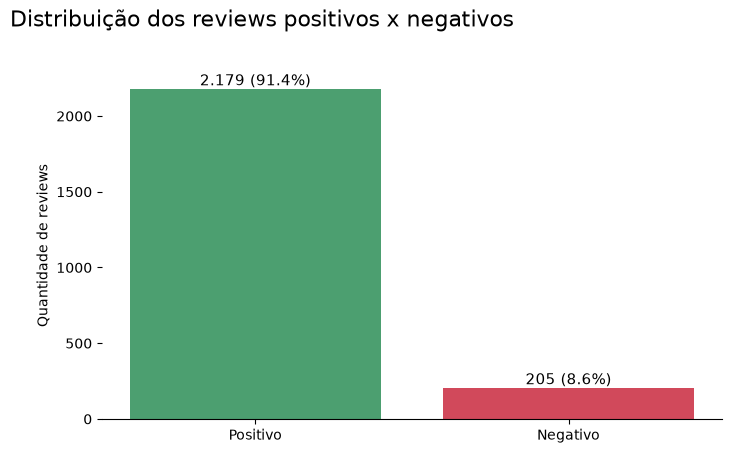

In [17]:
# 1 = review negativo (a classe que queremos encontrar) | 0 = review positivo
df_limpo['negativo'] = 1 - df_limpo['feedback']

plot_distribuicao_alvo(df_limpo['negativo'], 'Distribuição dos reviews positivos x negativos',
                       'Distribuicao positivos x negativos')

📌 **Nota**
- 🔎 Apenas **8,6%** dos reviews são negativos (205 de 2.384): base **desbalanceada**.
- ⚠️ Um modelo que dissesse "todo review é positivo" acertaria **91,4%** e seria inútil. Por isso a **acurácia não serve** como métrica principal, e olhamos a **precisão, o recall e o F1 da classe negativa**.
- ✅ Para facilitar a leitura, invertemos o alvo: **`negativo = 1`** é a classe que queremos encontrar.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS

A EDA ajuda a entender **como clientes satisfeitos e insatisfeitos escrevem**. Cada hipótese tem um gráfico e uma conclusão.

### 3.1. Criação das Hipóteses

| # | Hipótese | Tipo |
|---|---|---|
| H1 | A maioria dos clientes dá nota máxima (5) | Individual |
| H2 | A maioria dos reviews é curta (menos de 100 caracteres) | Individual |
| H3 | Reviews negativos são mais longos que os positivos | Combinada |
| H4 | Algumas variações do produto concentram mais reviews negativos | Combinada |
| H5 | Palavras de negação ("not", "no") aparecem mais nos reviews negativos | Combinada |
| H6 | Reviews negativos falam de defeitos e funcionamento; os positivos, de uso e diversão | Combinada |

### 3.2. Hipóteses Individuais (colunas isoladas)

#### H1 – A maioria dos clientes dá nota máxima (5)

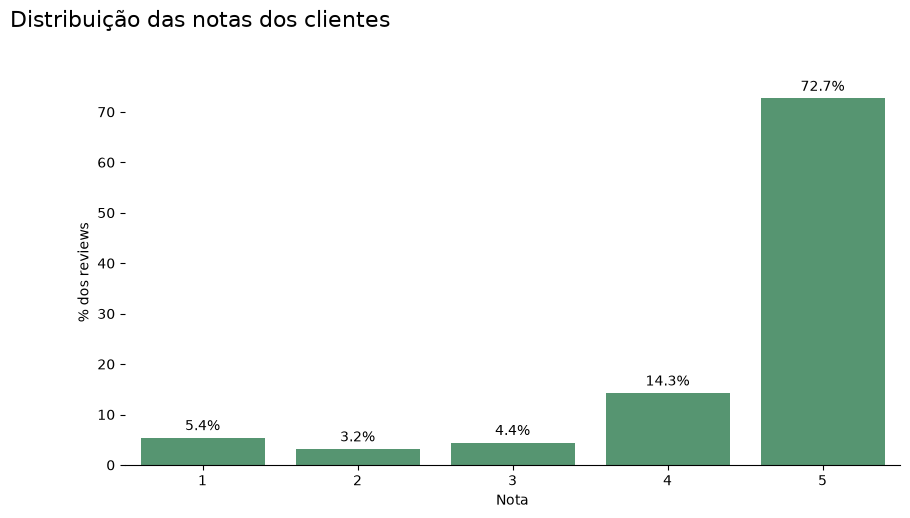

In [18]:
notas = df_limpo['rating'].value_counts(normalize=True).sort_index() * 100
plot_barras(notas, 'Distribuição das notas dos clientes', 'Distribuicao das notas',
            xlabel='Nota', ylabel='% dos reviews', formato='{:.1f}%')

✅ **Verdadeira.** **72,7%** dos reviews têm nota 5, e somando a nota 4 chegam a **87%**. Apenas **8,6%** têm nota 1 ou 2 (os negativos).

#### H2 – A maioria dos reviews é curta (menos de 100 caracteres)

In [19]:
print(f"Reviews com menos de 100 caracteres: {(df_limpo['length'] < 100).mean():.1%}")

Reviews com menos de 100 caracteres: 57.8%


✅ **Verdadeira.** **57,8%** dos reviews têm menos de 100 caracteres: a maioria escreve uma ou duas frases curtas (ex.: *"Love my Echo!"*).

### 3.3. Hipóteses Combinadas (entre colunas)

#### H3 – Reviews negativos são mais longos que os positivos

,length,n_palavras
Positivo,75.0,14.0
Negativo,163.0,31.0


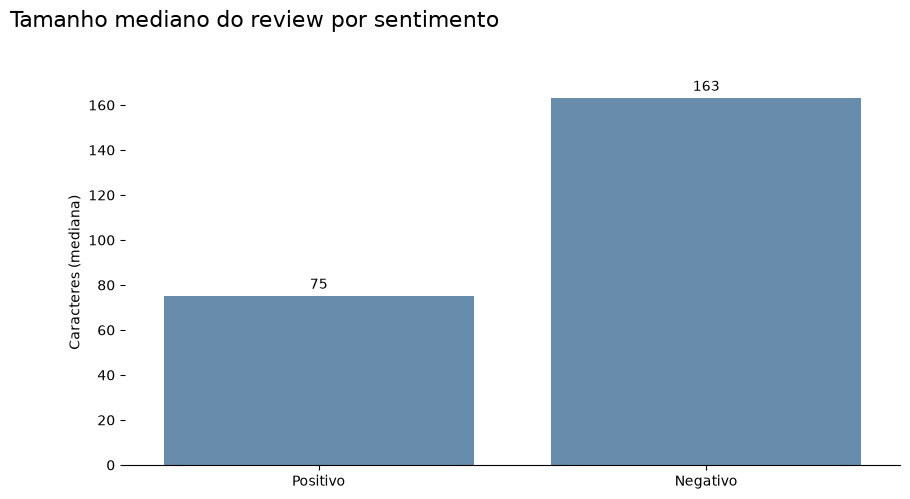

In [20]:
tamanho = df_limpo.groupby('negativo')[['length', 'n_palavras']].median()
tamanho.index = ['Positivo', 'Negativo']
display(tamanho)

plot_barras(tamanho['length'], 'Tamanho mediano do review por sentimento', 'Tamanho por sentimento',
            ylabel='Caracteres (mediana)', cor='#5B8DB8')

✅ **Verdadeira.** O review negativo mediano tem **163 caracteres (31 palavras)**, contra **75 caracteres (14 palavras)** do positivo: **mais que o dobro**. Cliente insatisfeito **explica o problema**, enquanto o satisfeito só elogia.

#### H4 – Algumas variações do produto concentram mais reviews negativos

,reviews,pct_negativos,nota_media
variation,,,
White,87,16.09,4.22
Black,258,13.18,4.25
Black Spot,235,12.77,4.34
White Show,82,12.20,4.30
Black Plus,261,10.34,4.38
White Plus,76,9.21,4.39
White Spot,104,8.65,4.40
Configuration: Fire TV Stick,336,7.44,4.61
Black Dot,247,6.88,4.47


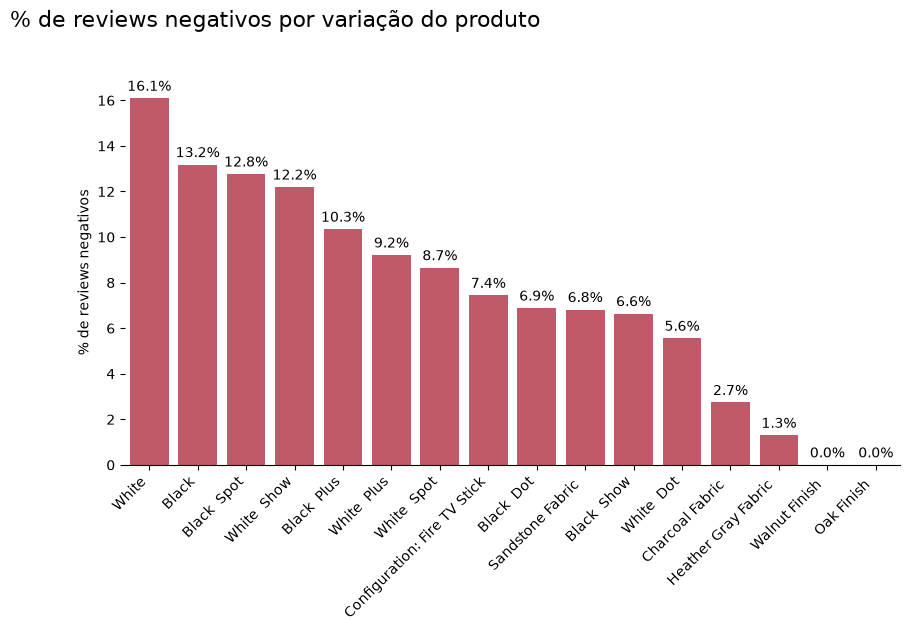

In [21]:
por_variacao = (df_limpo.groupby('variation')
                .agg(reviews=('negativo', 'size'), pct_negativos=('negativo', 'mean'), nota_media=('rating', 'mean'))
                .sort_values('pct_negativos', ascending=False))
por_variacao['pct_negativos'] *= 100
display(por_variacao.round(2))

plot_barras(por_variacao['pct_negativos'], '% de reviews negativos por variação do produto',
            '% negativos por variacao', ylabel='% de reviews negativos', cor='#D1495B', formato='{:.1f}%')

✅ **Verdadeira, com ressalvas.**
- 🔎 **White** (16,1%), **Black** (13,2%) e **Black Spot** (12,8%) têm a maior proporção de reviews negativos.
- 🔎 Os modelos com tecido, **Charcoal Fabric** (2,7%) e **Heather Gray Fabric** (1,3%), quase não recebem críticas.
- ⚠️ Cada variação corresponde a um **produto diferente** (Echo, Dot, Spot, Show, Plus), então a diferença provavelmente é do **modelo do aparelho**, e não da cor. Algumas variações têm poucos reviews (ex.: Walnut Finish, com 5).

#### H5 – Palavras de negação aparecem mais nos reviews negativos

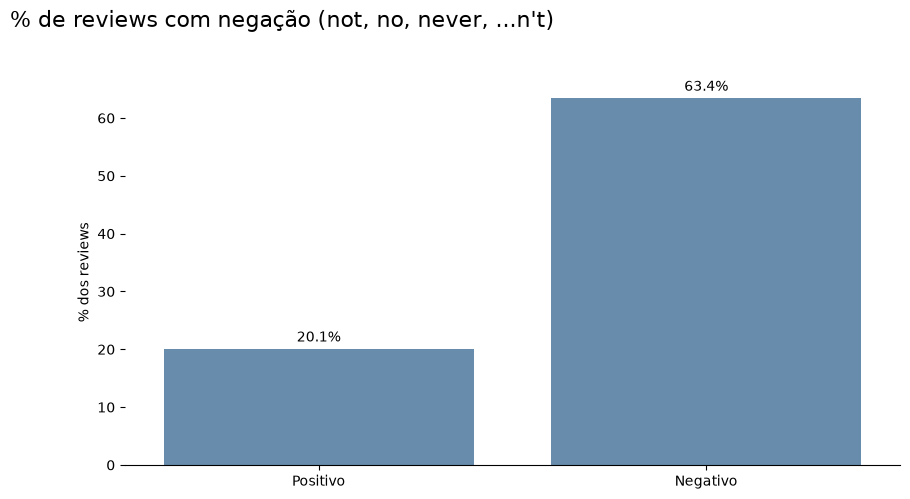

In [22]:
tem_negacao = df_limpo['verified_reviews'].str.lower().str.contains(r"\b(?:not|no|never)\b|n't\b", regex=True)
negacao = tem_negacao.groupby(df_limpo['negativo']).mean() * 100
negacao.index = ['Positivo', 'Negativo']

plot_barras(negacao, '% de reviews com negação (not, no, never, ...n\'t)', 'Negacao por sentimento',
            ylabel='% dos reviews', cor='#5B8DB8', formato='{:.1f}%')

✅ **Verdadeira.** **63,4%** dos reviews negativos têm alguma negação, contra **20,1%** dos positivos: **3 vezes mais**.

> 💡 Isso justifica uma decisão importante da limpeza do texto: **não remover as negações** (*not*, *no*), que a versão original eliminava junto com as stopwords.

#### H6 – Reviews negativos falam de defeitos e funcionamento

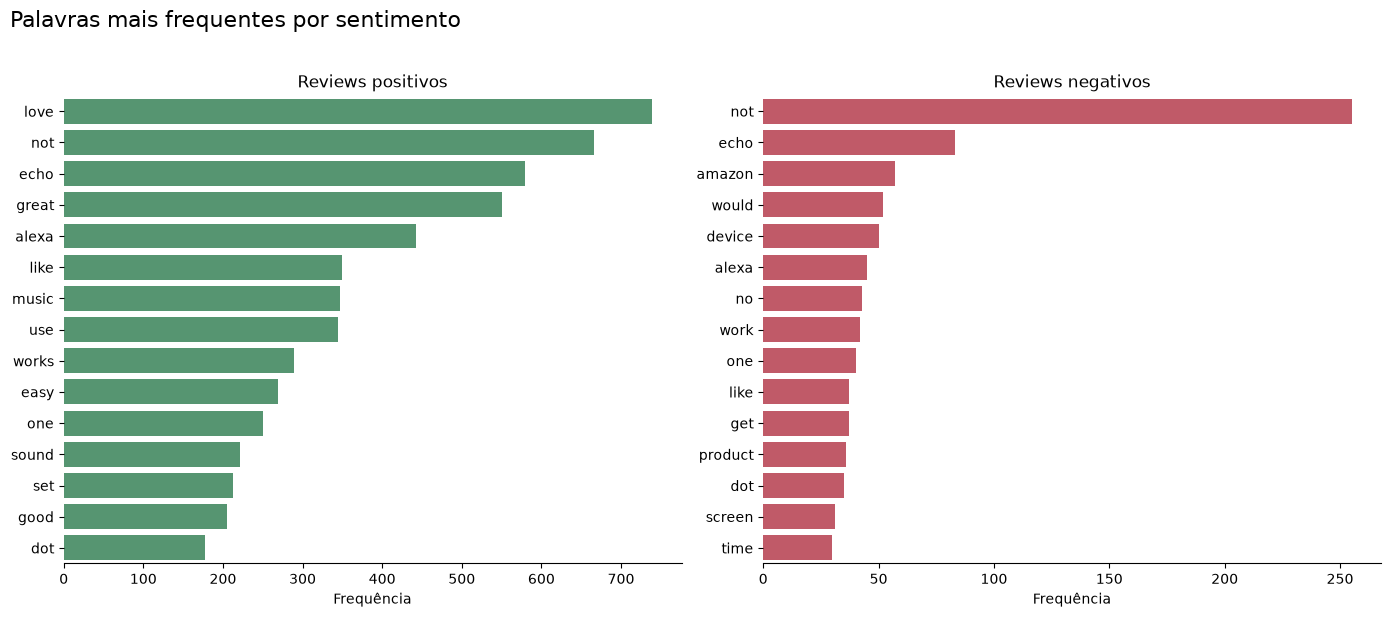

In [23]:
df_limpo['texto_limpo'] = df_limpo['verified_reviews'].apply(limpar_texto)

def palavras_mais_frequentes(textos, n=15):
    contador = CountVectorizer()
    matriz = contador.fit_transform(textos)
    return pd.Series(np.asarray(matriz.sum(axis=0)).ravel(),
                     index=contador.get_feature_names_out()).sort_values(ascending=False).head(n)

top_positivas = palavras_mais_frequentes(df_limpo.loc[df_limpo['negativo'] == 0, 'texto_limpo'])
top_negativas = palavras_mais_frequentes(df_limpo.loc[df_limpo['negativo'] == 1, 'texto_limpo'])

plot_top_palavras(top_positivas, top_negativas, 'Palavras mais frequentes por sentimento', 'Top palavras por sentimento')

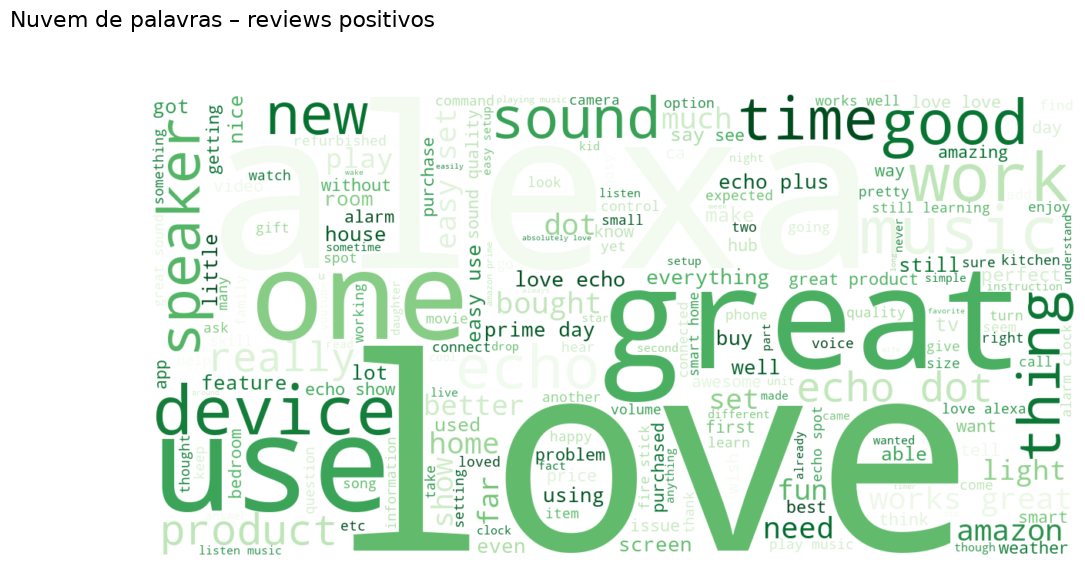

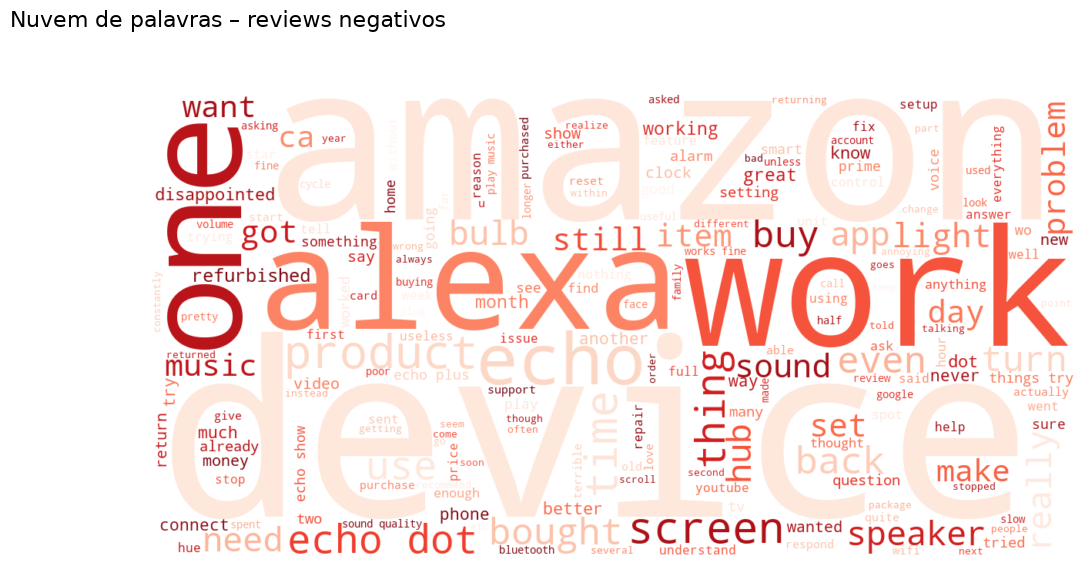

In [24]:
plot_nuvem(' '.join(df_limpo.loc[df_limpo['negativo'] == 0, 'texto_limpo']),
           'Nuvem de palavras – reviews positivos', 'Nuvem de palavras positivas', cor='Greens')
plot_nuvem(' '.join(df_limpo.loc[df_limpo['negativo'] == 1, 'texto_limpo']),
           'Nuvem de palavras – reviews negativos', 'Nuvem de palavras negativas', cor='Reds')

⚠️ **Parcialmente verdadeira.**
- 🔎 Palavras genéricas (*echo*, *alexa*, *one*) aparecem nos dois lados, porque descrevem o produto.
- 🔎 Nos **positivos** se destacam palavras de uso e satisfação: *love*, *great*, *music*, *easy*, *works*, *sound*.
- 🔎 Nos **negativos** aparecem *device*, *work*, *product*, *screen*, *amazon*: o cliente fala do **aparelho e do funcionamento**.
- 🔎 *not* é a palavra mais frequente dos reviews negativos e a 2ª dos positivos (ex.: *"not disappointed"*). Por isso o modelo precisa olhar o **conjunto das palavras**, e não uma palavra isolada.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Evidência |
|---|---|---|---|
| H1 | A maioria dá nota 5 | ✅ Verdadeira | 72,7% dos reviews |
| H2 | A maioria dos reviews é curta | ✅ Verdadeira | 57,8% com menos de 100 caracteres |
| H3 | Negativos são mais longos | ✅ Verdadeira | Mediana de 163 x 75 caracteres |
| H4 | Algumas variações têm mais negativos | ✅ Com ressalvas | White 16,1% x Charcoal Fabric 2,7% (diferença de produto) |
| H5 | Negações aparecem mais nos negativos | ✅ Verdadeira | 63,4% x 20,1% |
| H6 | Negativos falam de defeitos/funcionamento | ⚠️ Parcial | *device*, *work*, *screen* x *love*, *great*, *easy* |

> 💡 **Para o modelo:** o **texto** carrega quase toda a informação, e as **negações** são essenciais. A variação do produto entra como informação complementar.

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

| Variável | Como foi criada | Uso |
|---|---|---|
| `negativo` | `1 - feedback` | **Alvo** do modelo (1 = review negativo) |
| `length`, `n_palavras` | Nº de caracteres e de palavras | Apenas para a EDA |
| `texto_limpo` | `limpar_texto(verified_reviews)` | EDA (frequência de palavras). No modelo, a limpeza roda **dentro do pipeline** |

**Como funciona a limpeza (`limpar_texto`)**
1. Decodifica códigos HTML (alguns reviews trazem aspas como `&#34;`) e coloca tudo em minúsculas.
2. Transforma contrações negativas em "not" (*don't* → *do not*, *isn't* → *is not*).
3. Remove pontuação, números soltos de símbolos e emojis.
4. Remove **stopwords** (palavras muito comuns que não indicam sentimento, como *the*, *is*, *my*), **exceto as negações** *not*, *no* e *nor*.

> 💡 **Por que manter as negações?** Sem elas, *"it does **not** work"* e *"it works"* ficariam praticamente iguais para o modelo. A versão original removia essas palavras.

In [25]:
# Antes x depois da limpeza
df_limpo[['verified_reviews', 'texto_limpo']].sample(5, random_state=7)

,verified_reviews,texto_limpo
241,Good sound. Like it for music and scheduling. Like that i can get random thoughts recorded while I think about them. The jokes are cute!,good sound like music scheduling like get random thoughts recorded think jokes cute
1042,Very good,good
943,I love love love it.,love love love
395,Perfect condition! I love my echo,perfect condition love echo
194,I love it!,love


## 5 - EXPLORANDO AS CORRELAÇÕES

Como a base tem poucas colunas numéricas, a correlação ajuda a confirmar duas coisas: a relação entre a **nota** e o **rótulo**, e se o **tamanho do texto** tem relação com o sentimento.

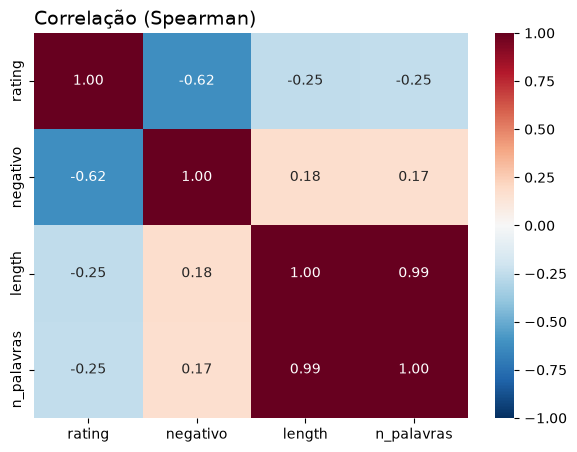

In [26]:
corr = df_limpo[['rating', 'negativo', 'length', 'n_palavras']].corr(method='spearman')

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlação (Spearman)', fontsize=14, loc='left')
salvar('Correlacao')
plt.show()

📌 **Nota**
- 🔎 `rating` × `negativo` = **-0,62**: esperado, já que o rótulo foi criado a partir da nota (por isso `rating` fica fora do modelo).
- 🔎 `length` × `negativo` = **+0,18**: reviews negativos tendem a ser mais longos (H3), mas a relação é **fraca**. O tamanho sozinho não identifica um review negativo; o que importa é **o que está escrito**.
- 🔎 `length` × `n_palavras` = **0,99**: medem praticamente a mesma coisa (por isso foram usadas só na EDA).

# FASE 03: MODELAGEM DOS DADOS

Agora vamos ensinar o computador a diferenciar reviews positivos de negativos. Para isso, o texto precisa virar **números**, e o modelo é escolhido pela capacidade de **encontrar os reviews negativos**.

## 1 - Leitura dos dados

Usamos apenas o que estaria disponível no momento de um review novo: o **texto** e a **variação do produto**. `rating` fica de fora (é a origem do rótulo), assim como `date`, `length` e `n_palavras`.

In [27]:
X = df_limpo[['verified_reviews', 'variation']]
y = df_limpo['negativo']

print(f'X: {X.shape} | y: {y.shape} | % negativos: {y.mean():.1%}')

X: (2384, 2) | y: (2384,) | % negativos: 8.6%


## 2 - Valores nulos

In [28]:
X.isnull().sum()

verified_reviews    0
variation           0
dtype: int64

✅ Nenhum valor nulo: os textos vazios já foram removidos na Fase 02.

## 3 - Transformação

Modelos não leem texto, então transformamos cada review em números com o **TF-IDF**:

| Etapa | O que faz |
|---|---|
| **Vocabulário** | Lista todas as palavras (e pares de palavras, como *"not working"*) que aparecem nos reviews de treino |
| **TF (frequência no review)** | Conta quantas vezes cada palavra aparece no review |
| **IDF (raridade na base)** | Dá **mais peso a palavras raras** e menos a palavras que aparecem em todo lugar (como *"echo"*) |

> 💡 **Analogia:** o TF-IDF funciona como um marca-texto: destaca as palavras que realmente diferenciam um review dos outros.

A variação do produto (`variation`) entra com **One-Hot Encoding** (uma coluna 0/1 por variação). As duas transformações ficam juntas em um `ColumnTransformer`.

In [29]:
def criar_preprocessador(ngram_range=(1, 2), min_df=2):
    return ColumnTransformer([
        ('texto', TfidfVectorizer(preprocessor=limpar_texto, ngram_range=ngram_range, min_df=min_df),
         'verified_reviews'),
        ('variacao', OneHotEncoder(handle_unknown='ignore'), ['variation']),
    ])

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

Dividimos em **80% treino** e **20% teste**, mantendo a mesma proporção de negativos nos dois (`stratify`). O **teste fica guardado** e só é usado uma vez, na avaliação final (Fase 04). Todas as escolhas (modelo, hiperparâmetros e limiar) são feitas com **validação cruzada dentro do treino**.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pd.DataFrame({
    'Reviews': [len(X_train), len(X_test)],
    'Negativos': [y_train.sum(), y_test.sum()],
    '% negativos': [f'{y_train.mean():.1%}', f'{y_test.mean():.1%}'],
}, index=['Treino', 'Teste'])

,Reviews,Negativos,% negativos
Treino,1907,164,8.6%
Teste,477,41,8.6%


### 4.2. Balancear os dados

Com só ~9% de negativos, o modelo tende a "ignorar" essa classe. Testamos duas formas de compensar:

| Técnica | Como funciona |
|---|---|
| **SMOTE** | Cria reviews negativos **sintéticos** (combinações dos existentes) para equilibrar as classes |
| **`class_weight='balanced'`** | Não cria dados: diz ao modelo que **errar um negativo custa mais** que errar um positivo |

> ⚠️ O balanceamento é aplicado **dentro do pipeline**, ou seja, só nos dados de treino de cada etapa da validação cruzada. Balancear antes de dividir faria o teste "enxergar" dados sintéticos criados a partir dele.

### 4.3. Seleção de Variáveis

Em textos, cada palavra vira uma variável. Usamos `min_df` para **descartar palavras raras** (que aparecem em menos de `min_df` reviews), que geralmente são erros de digitação ou ruído.

In [31]:
for min_df in [1, 2, 3]:
    vetorizador = TfidfVectorizer(preprocessor=limpar_texto, ngram_range=(1, 2), min_df=min_df)
    vetorizador.fit(X_train['verified_reviews'])
    print(f'min_df={min_df}: {len(vetorizador.vocabulary_):>6,} palavras/pares de palavras no vocabulário')

min_df=1: 22,136 palavras/pares de palavras no vocabulário


min_df=2:  3,911 palavras/pares de palavras no vocabulário


min_df=3:  2,140 palavras/pares de palavras no vocabulário


📌 **Nota**
- 🔎 Com `min_df=1`, o vocabulário tem **22.136 termos**. Exigindo que o termo apareça em pelo menos 2 reviews, cai para **3.911 (-82%)**: a grande maioria dos termos aparece **uma única vez** (erros de digitação, nomes, pares de palavras raros).
- ✅ O valor ideal de `min_df` é escolhido no **ajuste fino** (item 7), junto com os outros hiperparâmetros.

#### Relevância de cada variável: Random Forest e Informação Mútua

Nem toda variável ajuda o modelo da mesma forma. Esta etapa mede a relevância de cada uma usando dois métodos diferentes, que olham o problema por ângulos distintos:

| Método | Como funciona | Em palavras simples |
|---|---|---|
| **Random Forest** | treina várias árvores de decisão e mede o quanto cada variável ajuda a separar as classes | "quais perguntas o modelo mais usou para decidir" |
| **Informação Mútua** | mede o quanto conhecer a variável reduz a incerteza sobre o alvo | "quanto essa palavra, sozinha, conta sobre o sentimento" |

> Um cuidado técnico: os dois métodos só aceitam números. Por isso usamos a **matriz transformada** (cada palavra do TF-IDF e cada variação do produto vira uma coluna). O pré-processador é ajustado **só no treino original**, e só depois aplicamos o **SMOTE** à matriz transformada, para equilibrar as classes como no balanceamento do item 4.2. Se o SMOTE viesse antes, os reviews sintéticos poderiam "ensinar" ao vocabulário palavras que não existem nos dados reais.
>
> Na Informação Mútua, cada palavra é medida pela **presença** no review (aparece ou não), uma forma mais estável de comparar milhares de palavras.

In [32]:
import time

# Transformando o treino em números (ajuste no treino original, sem dados sintéticos)
prep_sel = criar_preprocessador()
X_train_t = prep_sel.fit_transform(X_train)
nomes_t = [nome.split('__')[-1] for nome in prep_sel.get_feature_names_out()]

# Balanceamento aplicado à matriz transformada (só para esta análise de relevância)
X_train_balanced_t, y_train_balanced = SMOTE(random_state=42).fit_resample(X_train_t, y_train)

print(f'treino transformado ............. {X_train_t.shape}')
print(f'treino transformado balanceado .. {X_train_balanced_t.shape} ({y_train_balanced.mean():.0%} negativos)')

treino transformado ............. (1907, 3927)
treino transformado balanceado .. (3486, 3927) (50% negativos)


not             0.0744
work            0.0254
device          0.0182
no              0.0148
get             0.0144
amazon          0.0137
love            0.0133
not work        0.0130
great           0.0129
back            0.0112
time            0.0107
would           0.0105
return          0.0094
working         0.0091
disappointed    0.0089
stopped         0.0079
thing           0.0069
try             0.0067
one             0.0065
product         0.0063


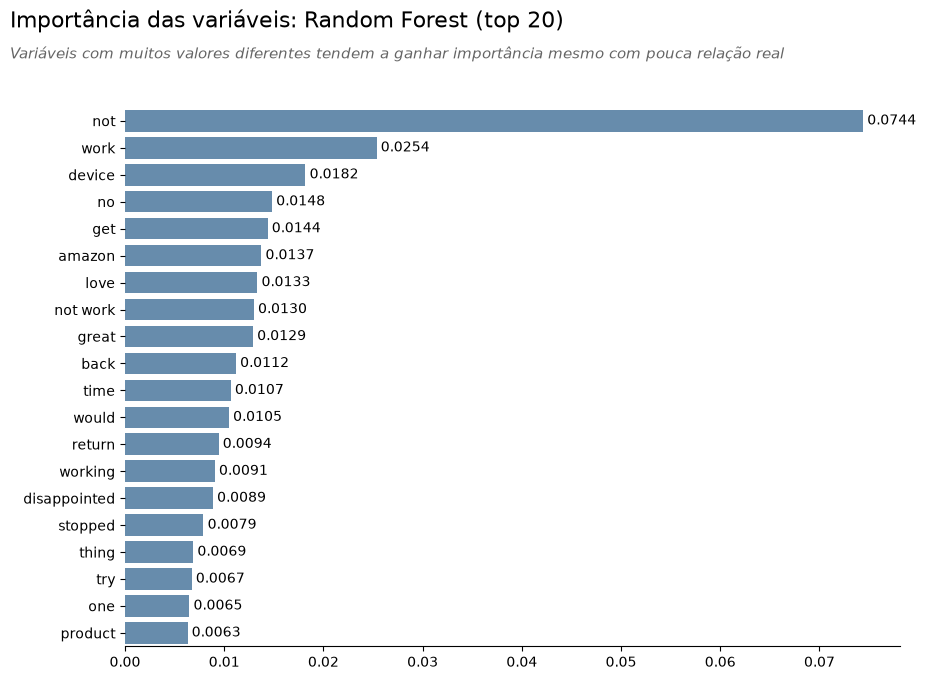

In [33]:
# Random Forest - classificação das melhores variáveis
importances = importancia_random_forest(X_train_balanced_t, y_train_balanced, nomes_t, semente=42)
print(importances.head(20).round(4).to_string())

plot_barras(importances.head(20), 'Importância das variáveis: Random Forest (top 20)',
            'Importancia RF (selecao)', horizontal=True, cor='#5B8DB8', formato='{:.4f}',
            subtitulo='Variáveis com muitos valores diferentes tendem a ganhar importância mesmo com pouca relação real')

informação mútua calculada em 63s

🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (top 20 de 3,927):
         feature   score
0            not  0.2461
1           work  0.0861
2         amazon  0.0852
3         device  0.0753
4           back  0.0746
5          would  0.0649
6             no  0.0563
7            get  0.0561
8       not work  0.0534
9            try  0.0451
10        return  0.0436
11       working  0.0436
12           one  0.0420
13          easy  0.0417
14  disappointed  0.0409
15       stopped  0.0405
16          time  0.0363
17        cannot  0.0359
18         money  0.0354
19          love  0.0334

colunas com informação mútua igual a zero: 6 de 3,927

🏆 TOP 5 FEATURES SELECIONADAS:
1. not: 0.246144
2. work: 0.086134
3. amazon: 0.085177
4. device: 0.075307
5. back: 0.074622

📊 Shape original: (3486, 3927)
📊 Shape após seleção: (3486, 5)
📊 Features selecionadas: ['not', 'work', 'amazon', 'device', 'back']


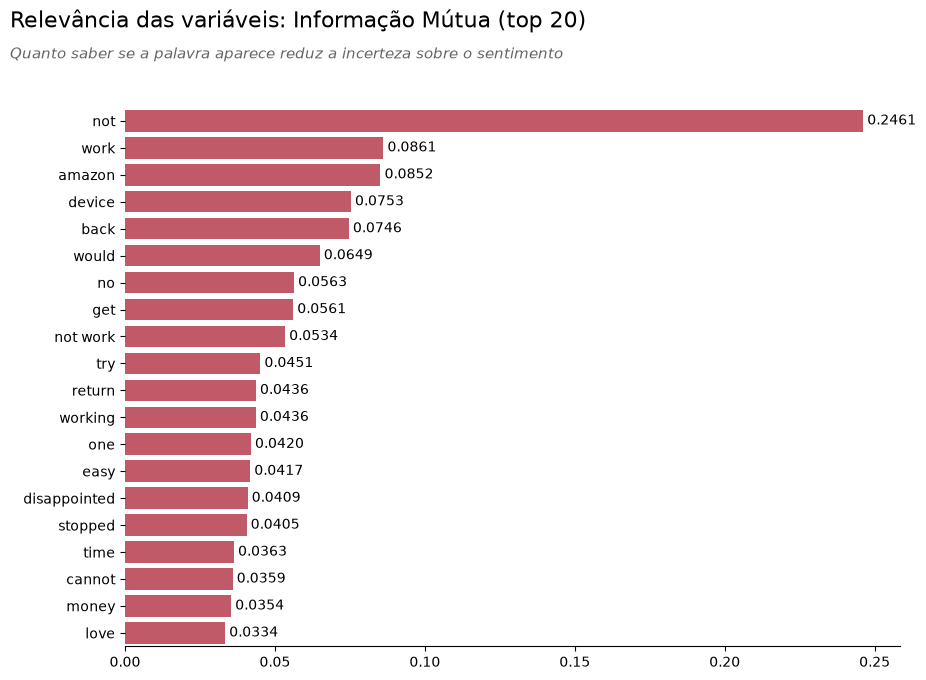

In [34]:
# Informação Mútua - ranking de todas as colunas e seleção das 5 melhores
t0 = time.time()
df_scores, selector = selecao_features(X_train_balanced_t, y_train_balanced, nomes_t, k=5, semente=42)
print(f'informação mútua calculada em {time.time() - t0:.0f}s\n')

print(f'🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (top 20 de {len(nomes_t):,}):')
print('=' * 50)
print(df_scores.head(20).round(4).to_string())
print(f"\ncolunas com informação mútua igual a zero: {(df_scores['score'] == 0).sum()} de {len(df_scores):,}")

print('\n🏆 TOP 5 FEATURES SELECIONADAS:')
print('=' * 50)
top_5_features = df_scores.head(5)['feature'].tolist()
for i, (feature, score) in enumerate(df_scores.head(5).itertuples(index=False), 1):
    print(f'{i}. {feature}: {score:.6f}')

X_train_selected = selector.transform(X_train_balanced_t)
print(f'\n📊 Shape original: {X_train_balanced_t.shape}')
print(f'📊 Shape após seleção: {X_train_selected.shape}')
print(f'📊 Features selecionadas: {top_5_features}')

plot_barras(df_scores.head(20).set_index('feature')['score'],
            'Relevância das variáveis: Informação Mútua (top 20)', 'Informacao mutua', horizontal=True,
            cor='#D1495B', formato='{:.4f}', subtitulo='Quanto saber se a palavra aparece reduz a incerteza sobre o sentimento')

In [35]:
# Comparação dos dois rankings (top 20 de cada método)
pd.DataFrame({'Random Forest': importances.head(20).index,
              'Informação Mútua': df_scores.head(20)['feature'].values}, index=range(1, 21))

,Random Forest,Informação Mútua
1,not,not
2,work,work
3,device,amazon
4,no,device
5,get,back
6,amazon,would
7,love,no
8,not work,get
9,great,not work
10,back,try


📌 **Nota**
- 🔎 O vocabulário de treino tem **3.927 colunas** (3.911 palavras e pares de palavras + 16 variações do produto). Com o SMOTE, o treino passa de 1.907 para 3.486 reviews, metade negativos.
- 🔎 Os dois métodos concordam no principal: **"not"** é, de longe, a variável mais relevante (Random Forest **0,074**; Informação Mútua **0,246**, quase 3 vezes a 2ª colocada). Isso confirma a decisão de **manter as negações** na limpeza do texto (a versão original as removia).
- 🔎 Em seguida vêm palavras de **defeito e funcionamento**: *work*, *device*, *amazon*, *back*, *return*, *stopped*, *disappointed* e o par *not work*. *back* e *return* indicam devolução do produto.
- 🔎 Palavras positivas como *love*, *great* e *easy* também aparecem: elas ajudam a separar as classes por **ausência** nos reviews negativos.
- 🔎 Nenhuma **variação do produto** está entre as 20 mais relevantes: o texto carrega quase toda a informação (como a H4 já indicava).
- 🔎 Só **6 de 3.927** colunas têm informação mútua igual a zero.
- ✅ **Decisão:** **não cortar** o vocabulário para as 5 melhores palavras. Com milhares de palavras, cada uma contribui um pouco, e a Regressão Logística com regularização (`C`, item 7) já reduz o peso das palavras pouco úteis. A seleção serve para **confirmar** que o modelo vai se apoiar em palavras que fazem sentido para o negócio, e o tamanho do vocabulário é definido pelo `min_df` no ajuste fino.

## 5 - Treinamento dos Algoritmos de Machine Learning

Comparamos 4 combinações com **validação cruzada estratificada de 5 partes** no treino: o treino é dividido em 5 pedaços, e cada modelo é treinado 5 vezes, sempre avaliado no pedaço que ficou de fora.

| Modelo | Ideia |
|---|---|
| **Naive Bayes + SMOTE** | Abordagem da versão original: calcula a probabilidade de cada palavra aparecer em reviews positivos ou negativos |
| **Regressão Logística + SMOTE** | Dá um **peso** para cada palavra e soma os pesos para chegar a uma probabilidade |
| **Regressão Logística (class_weight)** | Mesma ideia, compensando o desbalanceamento pelo peso dos erros |
| **LinearSVC (class_weight)** | Procura a "linha" que melhor separa positivos e negativos |

In [36]:
modelos = {
    'Naive Bayes + SMOTE': Pipeline([('prep', criar_preprocessador()), ('smote', SMOTE(random_state=42)),
                                     ('modelo', MultinomialNB())]),
    'Regressão Logística + SMOTE': Pipeline([('prep', criar_preprocessador()), ('smote', SMOTE(random_state=42)),
                                             ('modelo', LogisticRegression(max_iter=2000))]),
    'Regressão Logística (class_weight)': Pipeline([('prep', criar_preprocessador()),
                                                    ('modelo', LogisticRegression(max_iter=2000, class_weight='balanced'))]),
    'LinearSVC (class_weight)': Pipeline([('prep', criar_preprocessador()),
                                          ('modelo', LinearSVC(class_weight='balanced'))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['precision', 'recall', 'f1', 'average_precision']

resultados = {}
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas)
    resultados[nome] = {
        'Precisão': r['test_precision'].mean(),
        'Recall': r['test_recall'].mean(),
        'F1': r['test_f1'].mean(),
        'PR-AUC': r['test_average_precision'].mean(),
        'Tempo (s)': r['fit_time'].mean(),
    }

## 6 - Comparação do desempenho dos modelos

Todas as métricas são da **classe negativa** (a que queremos encontrar):

| Métrica | Pergunta que responde |
|---|---|
| **Precisão** | Dos reviews que o modelo marcou como negativos, quantos eram negativos de verdade? |
| **Recall** | Dos reviews negativos que existiam, quantos o modelo encontrou? |
| **F1** | Equilíbrio entre precisão e recall |
| **PR-AUC** | Qualidade do modelo **em todos os limiares** (não depende do corte de 0,5). Para referência, um modelo aleatório teria PR-AUC ≈ 0,09 (a % de negativos) |

In [37]:
comparacao = pd.DataFrame(resultados).T.sort_values('PR-AUC', ascending=False)
comparacao.style.format({'Precisão': '{:.1%}', 'Recall': '{:.1%}', 'F1': '{:.1%}', 'PR-AUC': '{:.3f}', 'Tempo (s)': '{:.2f}'}) \
    .highlight_max(subset=['Precisão', 'Recall', 'F1', 'PR-AUC'], color='#d4edda')

,Precisão,Recall,F1,PR-AUC,Tempo (s)
LinearSVC (class_weight),59.9%,53.1%,55.9%,0.602,0.91
Regressão Logística (class_weight),47.6%,70.1%,56.6%,0.574,1.31
Regressão Logística + SMOTE,50.9%,64.0%,56.6%,0.569,1.28
Naive Bayes + SMOTE,37.6%,74.4%,49.9%,0.550,1.26


📌 **Nota**

| Modelo | Precisão | Recall | F1 | PR-AUC |
|---|---|---|---|---|
| LinearSVC (class_weight) | **59,9%** | 53,1% | 55,9% | **0,602** |
| Regressão Logística (class_weight) | 47,6% | 70,1% | **56,6%** | 0,574 |
| Regressão Logística + SMOTE | 50,9% | 64,0% | **56,6%** | 0,569 |
| Naive Bayes + SMOTE *(abordagem da v1)* | 37,6% | **74,4%** | 49,9% | 0,550 |

- 🔎 O **Naive Bayes** (usado na versão original) encontra muitos negativos, mas com a **menor precisão**: quase 2 em cada 3 alertas seriam falsos.
- 🔎 O **LinearSVC** tem a melhor PR-AUC, mas o pior recall e **não gera probabilidades** (precisaríamos de um passo extra para escolher o limiar).
- 🔎 **SMOTE x class_weight** empatam na Regressão Logística: criar dados sintéticos **não trouxe ganho**.
- ✅ **Escolha: Regressão Logística (class_weight)**, com o melhor F1, recall alto, probabilidades para ajustar o limiar e **pesos interpretáveis** por palavra. Sem SMOTE, o pipeline fica mais simples.

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

Ajustamos a **Regressão Logística (class_weight)** com uma busca aleatória (`RandomizedSearchCV`, 25 combinações × 5 partes da validação cruzada):

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `C` | Força da regularização: valores baixos deixam o modelo mais "conservador", altos dão mais liberdade às palavras | 0,01 a 100 |
| `ngram_range` | Usar só palavras isoladas ou também pares (*"not working"*) | (1, 1) ou (1, 2) |
| `min_df` | Mínimo de reviews em que a palavra precisa aparecer | 1, 2 ou 3 |

A busca otimiza a **PR-AUC**, que mede a qualidade do modelo independentemente do limiar (o limiar é escolhido depois, no item 8).

In [38]:
espaco_busca = {
    'modelo__C': loguniform(0.01, 100),
    'prep__texto__ngram_range': [(1, 1), (1, 2)],
    'prep__texto__min_df': [1, 2, 3],
}

busca = RandomizedSearchCV(modelos['Regressão Logística (class_weight)'], espaco_busca, n_iter=25,
                           scoring='average_precision', cv=cv, random_state=42, n_jobs=-1)
busca.fit(X_train, y_train)

print(f'Melhores hiperparâmetros: {busca.best_params_}')
print(f'PR-AUC (validação cruzada): {busca.best_score_:.3f} (antes do ajuste: {resultados["Regressão Logística (class_weight)"]["PR-AUC"]:.3f})')

Melhores hiperparâmetros: {'modelo__C': np.float64(8.471801418819979), 'prep__texto__min_df': 1, 'prep__texto__ngram_range': (1, 1)}
PR-AUC (validação cruzada): 0.637 (antes do ajuste: 0.574)


📌 **Nota**
- 🔎 A PR-AUC subiu de **0,574 para 0,637** (+11%).
- 🔎 Melhores hiperparâmetros: `C ≈ 8,5` (menos regularização, dando mais peso às palavras), **só palavras isoladas** (`ngram_range=(1, 1)`) e `min_df=1`.
- 💡 Os pares de palavras (*"not working"*) não ajudaram: como as negações foram **mantidas** no texto, a palavra *not* sozinha já carrega a informação de negação.

### 7.3. Modelo final

O modelo final é a **Regressão Logística (class_weight)** com os hiperparâmetros encontrados. Além do bom desempenho, ela é **interpretável**: cada palavra tem um peso que mostra se ela empurra o review para positivo ou negativo (Fase 04, item 3).

In [39]:
modelo_final = busca.best_estimator_

## 8 - Otimização de limiar e calibração

### 8.1. Convertendo probabilidades em 0 ou 1

O modelo não diz apenas "negativo" ou "positivo": ele calcula uma **probabilidade** (um score de 0 a 1). O **limiar** é o ponto de corte: acima dele, o review é classificado como negativo. O padrão é **0,5**, mas não precisa ser.

| Limiar | Efeito |
|---|---|
| **Mais baixo** | Marca mais reviews como negativos → encontra mais clientes insatisfeitos (**recall ↑**), com mais alarmes falsos (**precisão ↓**) |
| **Mais alto** | Marca menos reviews → menos alarmes falsos (**precisão ↑**), mas deixa passar mais clientes insatisfeitos (**recall ↓**) |

### 8.2. Escolhendo o limiar

Para não usar o teste, geramos probabilidades **"fora da amostra" no treino** (`cross_val_predict`): cada review recebe a probabilidade de um modelo que **não o viu** no treinamento.

**Critério de negócio:** para o time de atendimento, **deixar um cliente insatisfeito sem resposta custa mais** do que ler alguns reviews a mais. Por isso escolhemos o **maior limiar que encontra pelo menos 75% dos reviews negativos** (recall ≥ 75%), o que mantém a maior precisão possível dentro dessa meta.

In [40]:
prob_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
precisao, recall, limiares = precision_recall_curve(y_train, prob_oof)

tabela_limiares = pd.DataFrame({'Limiar': limiares, 'Precisão': precisao[:-1], 'Recall': recall[:-1]})
tabela_limiares['F1'] = 2 * tabela_limiares['Precisão'] * tabela_limiares['Recall'] / (tabela_limiares['Precisão'] + tabela_limiares['Recall'])

META_RECALL = 0.75
limiar = tabela_limiares.loc[tabela_limiares['Recall'] >= META_RECALL, 'Limiar'].max()

# Alguns limiares para comparação
exemplos = [0.3, 0.4, 0.5, 0.6, limiar]
display(pd.DataFrame([tabela_limiares.iloc[(tabela_limiares['Limiar'] - l).abs().argmin()] for l in exemplos])
        .drop_duplicates().round(3).set_index('Limiar'))
print(f'Limiar escolhido: {limiar:.3f}')

,Precisão,Recall,F1
Limiar,,,
0.299,0.443,0.780,0.565
0.400,0.516,0.701,0.594
0.500,0.566,0.604,0.584
0.602,0.651,0.500,0.566
0.341,0.475,0.750,0.582


Limiar escolhido: 0.341


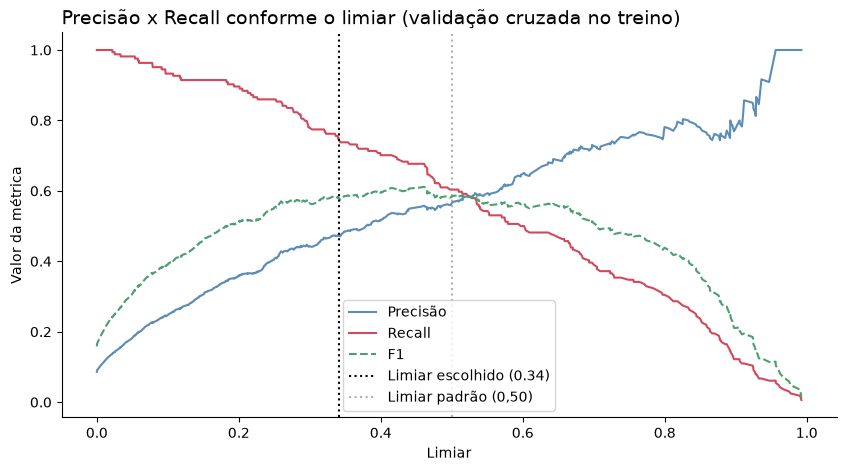

In [41]:
plt.figure(figsize=(10, 5))
plt.plot(tabela_limiares['Limiar'], tabela_limiares['Precisão'], label='Precisão', color='#5B8DB8')
plt.plot(tabela_limiares['Limiar'], tabela_limiares['Recall'], label='Recall', color='#D1495B')
plt.plot(tabela_limiares['Limiar'], tabela_limiares['F1'], label='F1', color='#4C9F70', ls='--')
plt.axvline(limiar, color='black', ls=':', label=f'Limiar escolhido ({limiar:.2f})')
plt.axvline(0.5, color='grey', ls=':', alpha=0.6, label='Limiar padrão (0,50)')
plt.xlabel('Limiar')
plt.ylabel('Valor da métrica')
plt.title('Precisão x Recall conforme o limiar (validação cruzada no treino)', fontsize=14, loc='left')
plt.legend()
sns.despine()
salvar('Escolha do limiar')
plt.show()

📌 **Nota**
- 🔎 Com o limiar padrão (0,50), o modelo encontraria **60%** dos negativos (precisão de 57%).
- ✅ O **limiar escolhido é 0,34**: encontra **75%** dos negativos, com precisão de **47,5%** (no treino, via validação cruzada).
- 💡 Na prática: de cada 2 reviews que o modelo sinaliza, ~1 é realmente negativo. Para o time de atendimento, ler um review "a mais" é um custo pequeno perto de perder um cliente insatisfeito.

### 8.3. Aplicando o limiar escolhido no teste

Agora, pela **primeira e única vez**, usamos o teste. Comparamos o limiar padrão (0,5) com o limiar escolhido.

In [42]:
prob_teste = modelo_final.predict_proba(X_test)[:, 1]

linhas = {}
for nome, corte in [('Limiar padrão (0,50)', 0.5), (f'Limiar escolhido ({limiar:.2f})', limiar)]:
    previsto = (prob_teste >= corte).astype(int)
    linhas[nome] = {'Precisão': precision_score(y_test, previsto), 'Recall': recall_score(y_test, previsto),
                    'F1': f1_score(y_test, previsto),
                    'Negativos encontrados': f'{((previsto == 1) & (y_test == 1)).sum()} de {y_test.sum()}',
                    'Alarmes falsos': ((previsto == 1) & (y_test == 0)).sum()}

pd.DataFrame(linhas).T

,Precisão,Recall,F1,Negativos encontrados,Alarmes falsos
"Limiar padrão (0,50)",0.638889,0.560976,0.597403,23 de 41,13
Limiar escolhido (0.34),0.537037,0.707317,0.610526,29 de 41,25


📌 **Nota**

| | Limiar 0,50 | Limiar 0,34 |
|---|---|---|
| Negativos encontrados | 23 de 41 (56%) | **29 de 41 (71%)** |
| Alarmes falsos | 13 | 25 |
| F1 | 59,7% | **61,1%** |

- 🔎 O novo limiar encontra **6 clientes insatisfeitos a mais**, ao custo de **12 reviews extras** para o time ler. No total, o modelo sinaliza 54 dos 477 reviews (**11%**), em vez de o time ler todos.
- 🔎 O recall no teste (71%) ficou um pouco abaixo da meta de 75%: o teste tem só 41 negativos, então **cada review vale 2,4 pontos percentuais**.

### 8.4. Calibração (versão simples)

Uma probabilidade é **calibrada** quando ela "significa o que diz": entre os reviews com score de 30%, cerca de 30% deveriam ser negativos. Como usamos `class_weight='balanced'`, o modelo tende a **superestimar** a probabilidade de negativo.

Comparamos o modelo original com uma versão calibrada (`CalibratedClassifierCV`, método sigmoide), usando as probabilidades fora da amostra no treino:
- **Brier score:** erro médio das probabilidades (**quanto menor, melhor**).
- **Curva de calibração:** quanto mais perto da diagonal, mais confiável a probabilidade.

Brier score – original:  0.0533
Brier score – calibrado: 0.0494
PR-AUC – original: 0.621 | calibrado: 0.609


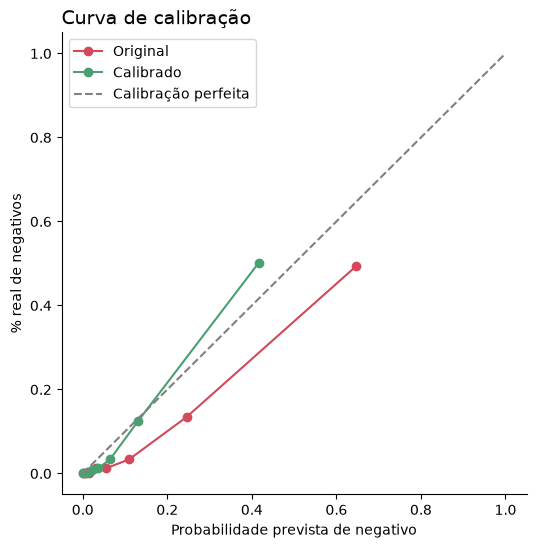

In [43]:
modelo_calibrado = CalibratedClassifierCV(modelo_final, method='sigmoid', cv=5)
prob_oof_calibrada = cross_val_predict(modelo_calibrado, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

print(f'Brier score – original:  {brier_score_loss(y_train, prob_oof):.4f}')
print(f'Brier score – calibrado: {brier_score_loss(y_train, prob_oof_calibrada):.4f}')
print(f'PR-AUC – original: {average_precision_score(y_train, prob_oof):.3f} | calibrado: {average_precision_score(y_train, prob_oof_calibrada):.3f}')

plt.figure(figsize=(6, 6))
for nome, prob, cor in [('Original', prob_oof, '#D1495B'), ('Calibrado', prob_oof_calibrada, '#4C9F70')]:
    frac_pos, prob_media = calibration_curve(y_train, prob, n_bins=8, strategy='quantile')
    plt.plot(prob_media, frac_pos, marker='o', label=nome, color=cor)
plt.plot([0, 1], [0, 1], ls='--', color='grey', label='Calibração perfeita')
plt.xlabel('Probabilidade prevista de negativo')
plt.ylabel('% real de negativos')
plt.title('Curva de calibração', fontsize=14, loc='left')
plt.legend()
sns.despine()
salvar('Curva de calibracao')
plt.show()

📌 **Nota**
- 🔎 Pela curva, o modelo original **superestima** o risco: quando ele prevê ~65% de chance de negativo, só ~49% são negativos de verdade (efeito do `class_weight`). A versão calibrada fica mais perto da diagonal.
- 🔎 O **Brier score** melhora de **0,0533 para 0,0494** (-7%), mas a PR-AUC cai um pouco (0,621 → 0,609).
- ✅ **Decisão:** manter o **modelo original**. Ele é mais simples, mantém os pesos por palavra interpretáveis, e o limiar (0,34) já foi escolhido sobre os scores dele. Por isso, no app o valor é apresentado como **"score de negatividade"**, e não como uma probabilidade exata.

# FASE 04: AVALIAÇÃO

Resultado final do modelo no **teste** (reviews que ele nunca viu), usando o limiar escolhido.

## 1 - Avaliando a Máquina Preditiva

              precision    recall  f1-score   support

Positivo (0)      0.972     0.943     0.957       436
Negativo (1)      0.537     0.707     0.611        41

    accuracy                          0.922       477
   macro avg      0.754     0.825     0.784       477
weighted avg      0.934     0.922     0.927       477

PR-AUC no teste: 0.595


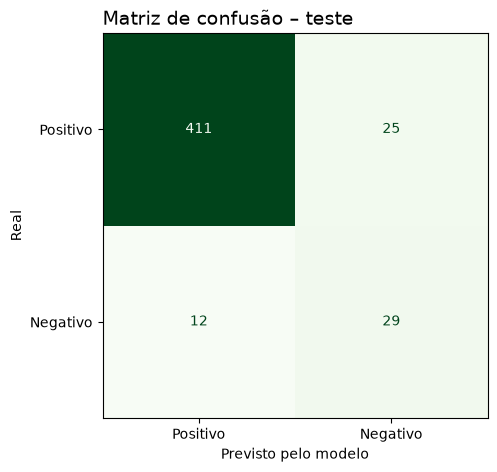

In [44]:
previsto_teste = (prob_teste >= limiar).astype(int)

print(classification_report(y_test, previsto_teste, target_names=['Positivo (0)', 'Negativo (1)'], digits=3))
print(f'PR-AUC no teste: {average_precision_score(y_test, prob_teste):.3f}')

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, previsto_teste, display_labels=['Positivo', 'Negativo'],
                                        cmap='Greens', colorbar=False, ax=ax)
ax.set(xlabel='Previsto pelo modelo', ylabel='Real')
plt.title('Matriz de confusão – teste', fontsize=14, loc='left')
salvar('Matriz de confusao')
plt.show()

📌 **Nota – resultado final no teste**

| Métrica (classe negativa) | Valor | Em linguagem de negócio |
|---|---|---|
| **Recall** | **70,7%** | De cada **10 clientes insatisfeitos**, o modelo encontra **7** |
| **Precisão** | **53,7%** | De cada **2 alertas**, ~**1** é realmente um review negativo |
| **F1** | **61,1%** | Equilíbrio entre os dois |
| **PR-AUC** | **0,595** | ~7x melhor que um modelo aleatório (0,086) |

- 🔎 A acurácia é de 92,2%, mas, como visto no item 2.7, ela não é a métrica certa aqui.
- 🔎 **Comparação com a versão original:** o F1 da classe negativa era **43%**, medido numa base com duplicadas, que favorecia o modelo. Agora é **61%**, numa avaliação mais rigorosa (sem duplicadas e com o teste usado uma única vez).

## 2 - Previsto x observado

Números ajudam, mas em NLP é importante **ler os textos**: onde o modelo acerta e onde ele erra?

In [45]:
resultado_teste = X_test.assign(real=y_test.values, previsto=previsto_teste, score=prob_teste.round(3))

print('✅ Negativos encontrados (acertos):')
display(resultado_teste.query('real == 1 and previsto == 1').sort_values('score', ascending=False).head(3))
print('❌ Negativos que passaram despercebidos:')
display(resultado_teste.query('real == 1 and previsto == 0').sort_values('score').head(3))
print('⚠️ Alarmes falsos (positivos marcados como negativos):')
display(resultado_teste.query('real == 0 and previsto == 1').sort_values('score', ascending=False).head(3))

✅ Negativos encontrados (acertos):


,verified_reviews,variation,real,previsto,score
988,Can't turn of &#34;things to try&#34; on the screen scroll. This is a big promotion device for Amazon. Packing it up and sending it back. They ...,Black Spot,1,1,0.993
544,product stopped working after return time ran out,Black,1,1,0.980
542,cant seem to get this thing to sink with my wireless not sure If I will be returning it will try one more time.,Black,1,1,0.967


❌ Negativos que passaram despercebidos:


,verified_reviews,variation,real,previsto,score
338,Alexa hardly came on..,Charcoal Fabric,1,0,0.020
1169,Fire HD does so much more. Over priced pair of speakers.,Black Show,1,0,0.072
384,Never could get it to work. A techie friend looked at it for me and said the adapter wasn't strong enough to power it and that it looked like it h...,Black,1,0,0.104


⚠️ Alarmes falsos (positivos marcados como negativos):


,verified_reviews,variation,real,previsto,score
1447,I try use with yale lock but isn’t work,White Plus,0,1,0.940
969,I bought this to replace a Dot in my bedroom. Already have a Show and a couple of full-sized Echo units in my house.The Spot is okay for what it i...,White Spot,0,1,0.899
1682,It appears to be working fine my first Echo stopped replying to my requests and I received the Echo plus very happy no problems no hassel exchange.,Black Plus,0,1,0.871


📌 **Nota**
- 🔎 **Acertos:** textos com sinais claros de problema (*"stopped working"*, *"sending it back"*, *"returning it"*).
- 🔎 **Negativos perdidos:** textos curtos ou indiretos, sem palavras típicas de reclamação (*"Alexa hardly came on.."*, *"Over priced pair of speakers"*). O modelo não entende ironia nem comparações.
- 🔎 **Alarmes falsos:** **8 dos 25** vêm de reviews **nota 3**, que o rótulo considera positivos, mas que contêm críticas (ex.: *"I try use with yale lock but isn't work"*). Ou seja, parte dos "erros" é **limitação do rótulo**, não do modelo.

## 3 - Quais variáveis mais influenciam o modelo?

Na Regressão Logística, cada palavra tem um **peso**:
- **Peso positivo:** a palavra empurra o review para **negativo**.
- **Peso negativo:** a palavra empurra o review para **positivo**.

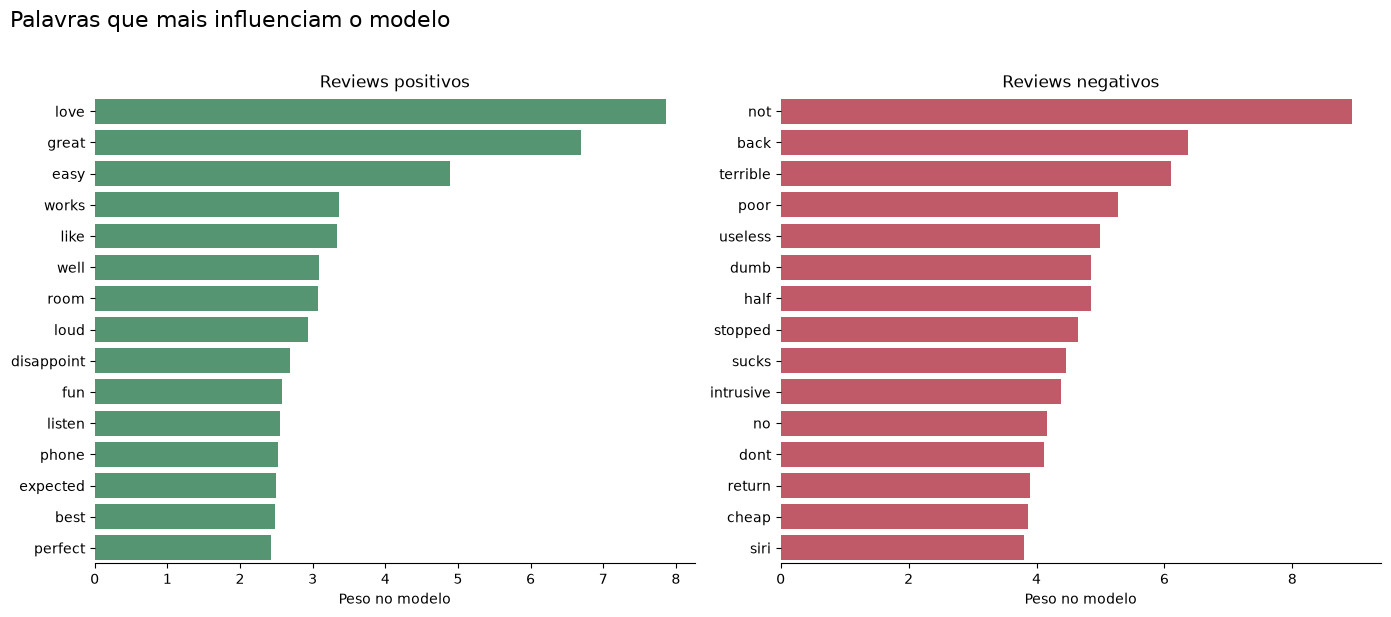

In [46]:
nomes = modelo_final.named_steps['prep'].get_feature_names_out()
pesos = pd.Series(modelo_final.named_steps['modelo'].coef_[0], index=nomes)
pesos_palavras = pesos[pesos.index.str.startswith('texto__')]
pesos_palavras.index = pesos_palavras.index.str.replace('texto__', '')

mais_negativas = pesos_palavras.sort_values(ascending=False).head(15)
mais_positivas = pesos_palavras.sort_values().head(15).abs()

plot_top_palavras(mais_positivas, mais_negativas, 'Palavras que mais influenciam o modelo',
                  'Palavras que mais influenciam o modelo', xlabel='Peso no modelo')

📌 **Nota**
- 🔎 **Palavras que mais indicam um review negativo:** *not* (a mais forte de todas), *back* e *return* (intenção de **devolver** o produto), *terrible*, *poor*, *useless*, *dumb*, *stopped*, *sucks*, *cheap* e *siri* (clientes **comparando com a concorrência**).
- 🔎 **Palavras que mais indicam um review positivo:** *love*, *great*, *easy*, *works*, *well*, *fun*, *best*, *perfect*.
- ⚠️ *disappoint* aparece, curiosamente, do lado **positivo**: das 44 vezes em que aparece, 26 são em reviews positivos, seja negada (*"does not disappoint"*) ou como uma crítica pontual dentro de um review nota 4 ou 5. É uma **limitação** de um modelo que olha palavras isoladas: ele não entende o contexto da frase.
- ✅ **Para o negócio:** reviews com *back*/*return* sinalizam risco de **devolução** e devem ter prioridade no atendimento.

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

O pipeline salvo já contém **tudo**: a limpeza do texto, o TF-IDF, o One-Hot Encoding e a Regressão Logística. Por isso ele recebe o review **cru**. Junto com ele salvamos o **limiar escolhido** e a lista de variações do produto (usada no app).

Antes de salvar, o modelo é **retreinado com todos os dados** (treino + teste), já que a avaliação terminou e mais dados ajudam o modelo.

In [47]:
modelo_producao = busca.best_estimator_
modelo_producao.fit(X, y)

with open('../Model/modelo_sentimento.pkl', 'wb') as arquivo:
    pickle.dump({'pipeline': modelo_producao, 'limiar': float(limiar),
                 'variacoes': sorted(df_limpo['variation'].unique())}, arquivo)

## 2 - Aplicando uma simulação

Testamos três reviews novos, incluindo um com **negação** (*"not worth"*), que a versão original tinha dificuldade em entender.

In [48]:
novos_reviews = pd.DataFrame({
    'verified_reviews': [
        'I love my Echo, the sound is great and Alexa answers everything!',
        'It stopped working after two weeks and customer support did not help.',
        'Not worth the money. The speaker is not loud enough.',
    ],
    'variation': ['Black  Dot', 'Charcoal Fabric ', 'White  Dot'],
})

novos_reviews['score_negativo'] = modelo_producao.predict_proba(novos_reviews)[:, 1].round(3)
novos_reviews['sentimento'] = np.where(novos_reviews['score_negativo'] >= limiar, 'Negativo 😞', 'Positivo 😀')
novos_reviews

,verified_reviews,variation,score_negativo,sentimento
0,"I love my Echo, the sound is great and Alexa answers everything!",Black Dot,0.002,Positivo 😀
1,It stopped working after two weeks and customer support did not help.,Charcoal Fabric,0.946,Negativo 😞
2,Not worth the money. The speaker is not loud enough.,White Dot,0.797,Negativo 😞


📌 **Nota**
- ✅ O elogio recebe score de **0,2%**, bem abaixo do limiar → **positivo**.
- ✅ A reclamação de defeito recebe **94,6%** → **negativo**.
- ✅ A frase com negação (*"Not worth the money... not loud enough"*) recebe **79,7%** → **negativo**. Sem manter as negações, palavras como *worth* e *loud* poderiam puxar o resultado para positivo.

# 💡 INSIGHTS

1. **Clientes insatisfeitos escrevem mais:** o review negativo mediano tem **o dobro do tamanho** do positivo. Eles explicam o problema, e isso é informação valiosa para o produto.
2. **"Not" é a palavra mais importante do modelo:** 63% dos reviews negativos têm alguma negação. Remover negações na limpeza (como na versão original) **apaga o principal sinal de insatisfação**.
3. **Intenção de devolução é detectável:** *back* e *return* estão entre as palavras mais ligadas a reviews negativos. Esses clientes devem ter **prioridade no atendimento**.
4. **Alguns produtos geram mais críticas:** White, Black e Black Spot têm de 13% a 16% de reviews negativos, contra menos de 3% dos modelos com acabamento em tecido. Vale uma análise de qualidade por produto.
5. **O modelo reduz o trabalho manual:** em vez de ler todos os reviews, o time lê **~11%** deles e encontra **7 em cada 10** clientes insatisfeitos.
6. **O rótulo tem limitações:** reviews nota 3 são considerados positivos, mas muitos contêm críticas. Eles respondem por 1/3 dos alarmes falsos.

# 🚀 PRÓXIMOS PASSOS

1. **Rótulo melhor:** revisar os reviews nota 3, hoje rotulados como positivos, e considerar uma classe "neutra".
2. **Mais dados negativos:** só 205 reviews negativos limitam o modelo; coletar mais exemplos é o ganho mais rápido.
3. **Modelos de linguagem:** testar embeddings ou um modelo pré-treinado (ex.: BERT/DistilBERT), que entendem contexto e sarcasmo.
4. **Monitoramento:** acompanhar em produção a precisão dos alertas (quantos o time confirma como negativos) e ajustar o limiar.
5. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

Para que o time de atendimento use o modelo **sem abrir o notebook**, criamos um app simples em **Streamlit**:
1. O usuário escreve (ou cola) um review e escolhe a variação do produto.
2. O app mostra se o review é **positivo ou negativo**, o **score de negatividade** e as **palavras que mais pesaram** na decisão.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz, depois de rodar a Fase 05, que gera `Model/modelo_sentimento.pkl`):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [49]:
%%writefile ../app.py
import pickle
from pathlib import Path

import pandas as pd
import streamlit as st

from src.texto import contribuicao_palavras

st.set_page_config(page_title="Análise de Sentimento 💬", page_icon="💬")
st.title("💬 Análise de Sentimento de Reviews")
st.markdown("Escreva um review **em inglês** de um produto Amazon Alexa e descubra se ele é **positivo** ou **negativo**.")

CAMINHO_MODELO = Path(__file__).parent / "Model" / "modelo_sentimento.pkl"


### Carregamento do modelo
@st.cache_resource
def carregar_modelo(caminho):
    with open(caminho, "rb") as arquivo:
        return pickle.load(arquivo)


if not CAMINHO_MODELO.exists():
    st.error("Modelo não encontrado. Execute o notebook até a Fase 05 para gerar `Model/modelo_sentimento.pkl`.")
    st.stop()

modelo = carregar_modelo(CAMINHO_MODELO)
pipeline, limiar = modelo["pipeline"], modelo["limiar"]

### Entrada do usuário
texto = st.text_area("Review", "It stopped working after two weeks and customer support did not help.", height=120)
variacao = st.selectbox("Variação do produto", modelo["variacoes"])

### Previsão
if st.button("Analisar sentimento", type="primary"):
    if not texto.strip():
        st.warning("Escreva um review para analisar.")
        st.stop()

    dados = pd.DataFrame({"verified_reviews": [texto], "variation": [variacao]})
    prob_negativo = pipeline.predict_proba(dados)[0, 1]

    if prob_negativo >= limiar:
        st.error(f"😞 **Review NEGATIVO** (score de negatividade: {prob_negativo:.0%})")
        st.markdown("➡️ **Ação sugerida:** encaminhar para o time de atendimento entrar em contato com o cliente.")
    else:
        st.success(f"😀 **Review POSITIVO** (score de negatividade: {prob_negativo:.0%})")

    st.caption(f"O review é classificado como negativo quando o score passa de {limiar:.0%} "
               "(limiar escolhido para encontrar a maioria dos clientes insatisfeitos).")

    # Palavras que mais pesaram na decisão
    palavras = contribuicao_palavras(pipeline, dados)
    if not palavras.empty:
        st.markdown("#### Palavras que mais pesaram")
        tabela = pd.DataFrame({
            "Palavra": palavras.index,
            "Empurra para": ["Negativo 😞" if v > 0 else "Positivo 😀" for v in palavras.values],
            "Peso": palavras.values.round(2),
        })
        st.dataframe(tabela, hide_index=True, width="stretch")

Overwriting ../app.py
